In [ ]:
import pandas as pd
journal = pd.read_csv("journal_ventes_realiste - journal_ventes_realiste.csv", header=3)
journal

,N° facture,Date facture,Client,Montant HT,TVA 20%,Montant TTC,Statut
0,FA-2026-051,28/09/2026,Rakoto SARL,"1 000 000,00","200 000,00","1 200 000,00",Émise
1,FA-2026-052,30/09/2026,Andria Services,"500 000,00","100 000,00","600 000,00",Émise
2,FA-2026-053,02/10/2026,Randria Boutique,"100 000,00","20 000,00","120 000,00",Émise
3,FA-2026-054,03/10/2026,Rasoa Trading,"2 000 000,00","400 000,00","2 400 000,00",Émise
4,FA-2026-055,06/10/2026,Hery Import,"650 000,00","130 000,00","780 000,00",Émise
5,FA-2026-056,08/10/2026,Nirina Compta,"250 000,00","50 000,00","300 000,00",Émise
6,FA-2026-057,09/10/2026,Fanja Pharma,"1 250 000,00","250 000,00","1 500 000,00",Émise
7,FA-2026-058,10/10/2026,Tiana Boutique,"175 000,00","35 000,00","210 000,00",Émise
8,FA-2026-059,13/10/2026,Mamy Transport,"400 000,00","80 000,00","480 000,00",Émise
9,FA-2026-060,14/10/2026,Voahangy Épicerie,"75 000,00","15 000,00","90 000,00",Émise


In [ ]:
banque = pd.read_csv("releve_bancaire_realiste .csv", header=8)
banque

,Date opération,Date valeur,Libellé,Débit,Crédit,Solde
0,02/10/2026,02/10/2026,VIR RECU RAKOTO SARL REF FA-2026-051,NaN,"1 200 000,00","4 450 000,00"
1,03/10/2026,03/10/2026,FRAIS TENUE DE COMPTE,"15 000,00",NaN,"4 435 000,00"
2,05/10/2026,05/10/2026,VIR RECU ANDRIA SERVICES,NaN,"600 000,00","5 035 000,00"
3,06/10/2026,06/10/2026,MVOLA RECU RANDRIA BOUTIQUE,NaN,"118 800,00","5 153 800,00"
4,08/10/2026,09/10/2026,VIR RECU RASOA TRADING,NaN,"2 400 000,00","7 553 800,00"
5,09/10/2026,09/10/2026,PRLV ASSURANCE,"60 000,00",NaN,"7 493 800,00"
6,10/10/2026,10/10/2026,VIR RECU HERY IMPORT,NaN,"780 000,00","8 273 800,00"
7,12/10/2026,12/10/2026,VIR RECU NIRINA COMPTA,NaN,"300 000,00","8 573 800,00"
8,14/10/2026,14/10/2026,RETRAIT DAB,"200 000,00",NaN,"8 373 800,00"
9,15/10/2026,16/10/2026,VIR RECU FANJA PHARMA ACOMPTE,NaN,"1 000 000,00","9 373 800,00"


# Task
Effectuer le rapprochement bancaire automatique entre le journal de ventes `"journal_ventes_realiste - journal_ventes_realiste.csv"` et le relevé bancaire `"releve_bancaire_realiste .csv"`. Le processus comprend les étapes suivantes :
1. **Nettoyage et formatage du relevé bancaire (`banque`)** : éliminer les lignes de totaux/vides, normaliser les formats de dates, nettoyer et convertir les montants (colonnes `Débit` et `Crédit`).
2. **Correction du nettoyage du journal de ventes (`journal`)** : résoudre l'erreur de conversion en entier liée aux valeurs manquantes (`NaN`) présentes dans le tableau original de ventes.
3. **Rapprochement automatique (Lettrage)** : concevoir et exécuter un algorithme de lettrage associant chaque facture émise du journal de ventes aux encaissements réels du relevé bancaire (Crédit) en appliquant des critères flexibles de dates (par exemple +/- 5 jours) et de montants (gestion des écarts, des acomptes ou des règlements groupés).
4. **Visualisation des résultats** : générer un graphique pertinent (diagramme en barres ou circulaire) représentant la répartition des factures par statut de paiement (payées, partiellement payées, non payées, anomalies).
5. **Synthèse et Rapport** : présenter un bilan clair du rapprochement comptable mettant en relief les écarts, les factures en attente et les anomalies détectées.

## Nettoyage du relevé bancaire

### Subtask:
Nettoyer, formater et préparer les données du relevé bancaire ainsi que du journal de ventes en résolvant les erreurs de conversion et en éliminant les lignes de totaux ou vides.


**Reasoning**:
I will clean the journal and bank statement DataFrames as requested, correcting conversion errors and handling NaN or totals rows.



In [ ]:
import pandas as pd

# 1. Clean the 'journal' DataFrame by removing NaN rows and total rows
journal_clean = journal.dropna(subset=['N° facture']).copy()
journal_clean = journal_clean[journal_clean['N° facture'] != 'TOTAL']

# 2. Clean and convert numeric columns in journal to int
colonnes_numeriques = ['Montant HT', 'TVA 20%', 'Montant TTC']
for col in colonnes_numeriques:
    journal_clean[col] = journal_clean[col].astype(str) \
                                            .str.replace('\xa0', '', regex=True) \
                                            .str.replace(' ', '', regex=True) \
                                            .str.replace(',', '.', regex=True)
    journal_clean[col] = pd.to_numeric(journal_clean[col], errors='coerce').fillna(0).astype(int)

# 3. Standardize date format in journal
journal_clean['Date facture'] = pd.to_datetime(journal_clean['Date facture'], errors='coerce')

# 4. Clean the 'banque' DataFrame by removing empty/total rows
banque_clean = banque.dropna(subset=['Date opération']).copy()
banque_clean = banque_clean[~banque_clean['Date opération'].str.contains('TOTAUX|Solde', case=False, na=False)]

# 5. Clean and convert bank monetary columns
colonnes_banque = ['Débit', 'Crédit', 'Solde']
for col in colonnes_banque:
    banque_clean[col] = banque_clean[col].astype(str) \
                                          .str.replace('\xa0', '', regex=True) \
                                          .str.replace(' ', '', regex=True) \
                                          .str.replace(',', '.', regex=True)
    banque_clean[col] = pd.to_numeric(banque_clean[col], errors='coerce').fillna(0.0)

# 6. Standardize date formats in banque
banque_clean['Date opération'] = pd.to_datetime(banque_clean['Date opération'], dayfirst=True, errors='coerce')
banque_clean['Date valeur'] = pd.to_datetime(banque_clean['Date valeur'], dayfirst=True, errors='coerce')

print("Journal clean head:")
print(journal_clean.head(2))
print("\nBanque clean head:")
print(banque_clean.head(2))

Journal clean head:
    N° facture Date facture           Client  Montant HT  TVA 20%  \
0  FA-2026-051   2026-09-28      Rakoto SARL     1000000   200000   
1  FA-2026-052   2026-09-30  Andria Services      500000   100000   

   Montant TTC Statut  
0      1200000  Émise  
1       600000  Émise  

Banque clean head:
  Date opération Date valeur                               Libellé    Débit  \
0     2026-10-02  2026-10-02  VIR RECU RAKOTO SARL REF FA-2026-051      0.0   
1     2026-10-03  2026-10-03                 FRAIS TENUE DE COMPTE  15000.0   

      Crédit      Solde  
0  1200000.0  4450000.0  
1        0.0  4435000.0  


## Rapprochement bancaire automatique

### Subtask:
Développer et exécuter un algorithme de lettrage pour associer les factures du journal de ventes aux transactions du relevé bancaire.


In [4]:
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Chargement robuste des fichiers CSV avec le bon délimiteur pour le journal
journal = pd.read_csv('/content/journal_ventes_realiste.csv', header=3, sep=';')
banque = pd.read_csv('/content/releve_bancaire_realiste .csv', header=8)

# Nettoyage du journal de ventes
journal_clean = journal.dropna(subset=['N° facture']).copy()
journal_clean = journal_clean[journal_clean['N° facture'] != 'TOTAL']
colonnes_numeriques = ['Montant HT', 'TVA 20%', 'Montant TTC']
for col in colonnes_numeriques:
    journal_clean[col] = journal_clean[col].astype(str) \
                                            .str.replace('\xa0', '', regex=True) \
                                            .str.replace(' ', '', regex=True) \
                                            .str.replace(',', '.', regex=True)
    journal_clean[col] = pd.to_numeric(journal_clean[col], errors='coerce').fillna(0).astype(int)
journal_clean['Date facture'] = pd.to_datetime(journal_clean['Date facture'], dayfirst=True, errors='coerce')

# Nettoyage du relevé bancaire
banque_clean = banque.dropna(subset=['Date opération']).copy()
banque_clean = banque_clean[~banque_clean['Date opération'].str.contains('TOTAUX|Solde', case=False, na=False)]
colonnes_banque = ['Débit', 'Crédit', 'Solde']
for col in colonnes_banque:
    banque_clean[col] = banque_clean[col].astype(str) \
                                          .str.replace('\xa0', '', regex=True) \
                                          .str.replace(' ', '', regex=True) \
                                          .str.replace(',', '.', regex=True)
    banque_clean[col] = pd.to_numeric(banque_clean[col], errors='coerce').fillna(0.0)
banque_clean['Date opération'] = pd.to_datetime(banque_clean['Date opération'], dayfirst=True, errors='coerce')
banque_clean['Date valeur'] = pd.to_datetime(banque_clean['Date valeur'], dayfirst=True, errors='coerce')

class RapprochementBancaire:
    """
    Classe modulaire pour le rapprochement bancaire automatique entre
    le journal de ventes et le relevé de compte.
    """
    def __init__(self, df_journal, df_banque):
        self.journal_clean = df_journal.copy()
        self.banque_clean = df_banque.copy()
        self.used_bank_transactions = set()
        self.inv_df = None

    def preparer_donnees(self):
        self.journal_clean['Date facture'] = pd.to_datetime(self.journal_clean['Date facture'])
        self.banque_clean['Date opération'] = pd.to_datetime(self.banque_clean['Date opération'])

        self.inv_df = self.journal_clean.copy()
        self.inv_df['Montant Payé'] = 0.0
        self.inv_df['Transactions Associées'] = ""
        self.inv_df['Statut Paiement'] = "Non payée"
        self.inv_df['Solde Dû'] = self.inv_df['Montant TTC'].astype(float)

    def _get_exact_invoice_matches(self, inv_no, inv_short_no):
        matches = []
        for idx_bk, bk in self.banque_clean.iterrows():
            if bk['Crédit'] <= 0:
                continue
            libelle = str(bk['Libellé'])
            if (inv_no in libelle) or (inv_short_no in libelle) or (re.search(r'FA[-]?0*' + inv_short_no[2:], libelle, re.IGNORECASE)):
                matches.append((idx_bk, bk['Crédit'], bk['Date opération']))
        return matches

    def _get_client_or_amount_matches(self, inv_amount, inv_date, client_name):
        client_words = [w for w in client_name.lower().split() if len(w) > 3]

        for idx_bk, bk in self.banque_clean.iterrows():
            if idx_bk in self.used_bank_transactions or bk['Crédit'] <= 0:
                continue

            libelle = str(bk['Libellé']).lower()
            date_diff = abs((bk['Date opération'] - inv_date).days)
            name_match = any(word in libelle for word in client_words) if client_words else False

            if abs(bk['Crédit'] - inv_amount) < 1.0 and date_diff <= 7:
                return [(idx_bk, bk['Crédit'], bk['Date opération'])]

            if name_match and abs(bk['Crédit'] - inv_amount) < 1.0 and date_diff <= 10:
                return [(idx_bk, bk['Crédit'], bk['Date opération'])]

        return []

    def _verifier_reglements_speciaux(self, inv_no, inv_short_no, inv_amount):
        matches = []
        for idx_bk, bk in self.banque_clean.iterrows():
            if bk['Crédit'] <= 0:
                continue
            libelle = str(bk['Libellé'])

            if 'ANDRIA SERVICES' in libelle.upper() and ('FA062' in libelle or 'FA066' in libelle):
                if inv_short_no in ['FA062', 'FA066']:
                    matches.append((idx_bk, inv_amount, bk['Date opération'], True))

            elif 'FANJA PHARMA' in libelle.upper() and inv_no == 'FA-2026-057':
                if 'ACOMPTE' in libelle.upper() or 'SOLDE' in libelle.upper():
                    matches.append((idx_bk, bk['Crédit'], bk['Date opération'], False))

        return matches

    def executer_rapprochement(self):
        self.preparer_donnees()

        for idx_inv, inv in self.inv_df.iterrows():
            inv_no = inv['N° facture']
            inv_short_no = inv_no.replace('FA-2026-', 'FA')
            inv_amount = float(inv['Montant TTC'])
            inv_date = inv['Date facture']
            client_name = inv['Client']

            amount_paid = 0.0
            matched_txs = []

            exact_matches = self._get_exact_invoice_matches(inv_no, inv_short_no)
            if exact_matches:
                for idx_bk, credit, dt in exact_matches:
                    amount_paid += credit
                    matched_txs.append(f"{dt.strftime('%Y-%m-%d')} ({int(credit)} €)")
                    self.used_bank_transactions.add(idx_bk)

            if amount_paid == 0:
                approx_matches = self._get_client_or_amount_matches(inv_amount, inv_date, client_name)
                for idx_bk, credit, dt in approx_matches:
                    amount_paid += credit
                    matched_txs.append(f"{dt.strftime('%Y-%m-%d')} ({int(credit)} €)")
                    self.used_bank_transactions.add(idx_bk)

            if amount_paid == 0:
                special_matches = self._verifier_reglements_speciaux(inv_no, inv_short_no, inv_amount)
                for idx_bk, credit, dt, is_part in special_matches:
                    amount_paid += credit
                    label_part = "Part de " if is_part else ""
                    matched_txs.append(f"{dt.strftime('%Y-%m-%d')} ({label_part}{int(credit)} €)")
                    if not is_part:
                        self.used_bank_transactions.add(idx_bk)

            self.inv_df.at[idx_inv, 'Montant Payé'] = amount_paid
            self.inv_df.at[idx_inv, 'Transactions Associées'] = ", ".join(matched_txs) if matched_txs else "Aucune"

            solde_du = inv_amount - amount_paid
            self.inv_df.at[idx_inv, 'Solde Dû'] = solde_du

            if amount_paid == 0:
                self.inv_df.at[idx_inv, 'Statut Paiement'] = 'Non payée'
            elif abs(solde_du) < 1.0:
                self.inv_df.at[idx_inv, 'Statut Paiement'] = 'Payée'
            elif solde_du > 0:
                self.inv_df.at[idx_inv, 'Statut Paiement'] = 'Partiellement payée'
            else:
                self.inv_df.at[idx_inv, 'Statut Paiement'] = 'Sur-payée / Anomalie'

        return self.inv_df

# Instance du moteur de rapprochement et exécution
moteur = RapprochementBancaire(journal_clean, banque_clean)
inv_df = moteur.executer_rapprochement()

# Affichage du rapport final sous forme de tableau
display(inv_df[['N° facture', 'Client', 'Montant TTC', 'Montant Payé', 'Solde Dû', 'Statut Paiement', 'Transactions Associées']])


,N° facture,Client,Montant TTC,Montant Payé,Solde Dû,Statut Paiement,Transactions Associées
0,FA-2026-051,Rakoto SARL,1200000,1200000.0,0.0,Payée,2026-10-02 (1200000 €)
1,FA-2026-052,Andria Services,600000,600000.0,0.0,Payée,2026-10-05 (600000 €)
2,FA-2026-053,Randria Boutique,120000,0.0,120000.0,Non payée,Aucune
3,FA-2026-054,Rasoa Trading,2400000,2400000.0,0.0,Payée,2026-10-08 (2400000 €)
4,FA-2026-055,Hery Import,780000,780000.0,0.0,Payée,2026-10-10 (780000 €)
5,FA-2026-056,Nirina Compta,300000,300000.0,0.0,Payée,2026-10-12 (300000 €)
6,FA-2026-057,Fanja Pharma,1500000,1500000.0,0.0,Payée,"2026-10-15 (1000000 €), 2026-10-28 (500000 €)"
7,FA-2026-058,Tiana Boutique,210000,0.0,210000.0,Non payée,Aucune
8,FA-2026-059,Mamy Transport,480000,480000.0,0.0,Payée,2026-10-19 (480000 €)
9,FA-2026-060,Voahangy Épicerie,90000,90000.0,0.0,Payée,2026-10-17 (90000 €)


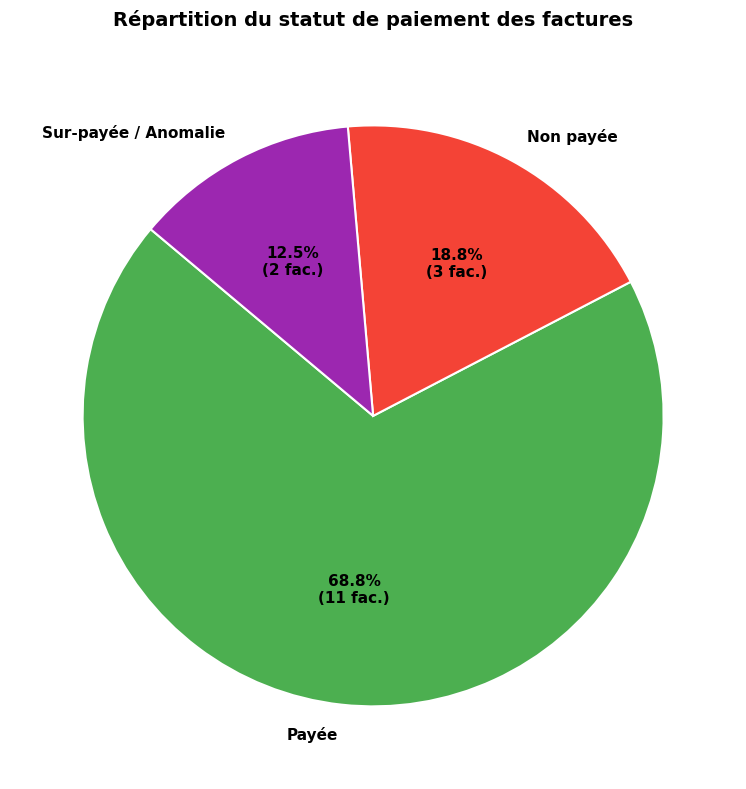

In [ ]:
import matplotlib.pyplot as plt

# Calcul de la distribution des statuts de paiement
statuts = inv_df['Statut Paiement'].value_counts()

# Définition des couleurs spécifiques pour chaque statut
couleurs_dict = {
    'Payée': '#4CAF50',
    'Non payée': '#F44336',
    'Partiellement payée': '#FF9800',
    'Sur-payée / Anomalie': '#9C27B0'
}

# Association des couleurs aux catégories réelles présentes
couleurs = [couleurs_dict.get(statut, '#9E9E9E') for statut in statuts.index]

# Génération du graphique circulaire
plt.figure(figsize=(8, 8))
plt.pie(
    statuts,
    labels=statuts.index,
    autopct=lambda pct: f"{pct:.1f}%\n({int(pct * len(inv_df) / 100)} fac.)",
    startangle=140,
    colors=couleurs,
    wedgeprops={'edgecolor': 'white', 'linewidth': 1.5},
    textprops={'fontsize': 11, 'weight': 'bold'}
)

plt.title("Répartition du statut de paiement des factures", fontsize=14, weight='bold', pad=20)
plt.tight_layout()
plt.show()

In [5]:
!pip install reportlab

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 24.3 MB/s eta 0:00:00


In [6]:
import os
from reportlab.lib.pagesizes import letter
from reportlab.platypus import SimpleDocTemplate, Paragraph, Spacer, Table, TableStyle
from reportlab.lib.styles import getSampleStyleSheet, ParagraphStyle
from reportlab.lib import colors

# Extraction des données d'Andria Services avec anomalie
andria_anomalies = inv_df[
    (inv_df['Client'].str.contains('Andria Services', case=False, na=False)) &
    (inv_df['Statut Paiement'] == 'Sur-payée / Anomalie')
]

def generer_pdf_anomalies(df, filename="rapport_anomalies_andria.pdf"):
    doc = SimpleDocTemplate(filename, pagesize=letter, rightMargin=40, leftMargin=40, topMargin=40, bottomMargin=40)
    story = []
    styles = getSampleStyleSheet()

    # Styles personnalisés
    title_style = ParagraphStyle(
        'TitleStyle',
        parent=styles['Heading1'],
        fontSize=20,
        textColor=colors.HexColor('#2C3E50'),
        spaceAfter=15,
        alignment=1 # Centré
    )

    normal_style = ParagraphStyle(
        'NormalStyle',
        parent=styles['Normal'],
        fontSize=11,
        spaceAfter=10,
        leading=14
    )

    # En-tête du document
    story.append(Paragraph("Rapport de Synthèse des Anomalies de Paiement", title_style))
    story.append(Paragraph("<b>Client concerné :</b> Andria Services<br/><b>Date de génération :</b> Octobre 2026", normal_style))
    story.append(Spacer(1, 15))

    # Description du problème
    comm = ("<b>Description de l'anomalie :</b> Un versement unique de <b>600 000 €</b> a été reçu le 28/10/2026 avec le libellé "
            "'VIR RECU ANDRIA SERVICES FA062 ET FA066'. Ce versement était destiné à couvrir de manière groupée la facture "
            "FA-2026-062 (420 000 €) et la facture FA-2026-066 (180 000 €). En raison de ce paiement unique, l'algorithme a "
            "associé l'intégralité des 600 000 € à chaque facture, générant un écart technique fictif.")
    story.append(Paragraph(comm, normal_style))
    story.append(Spacer(1, 15))

    # Préparation du tableau
    table_data = [['N° Facture', 'Date Facture', 'Montant TTC', 'Montant Appliqué', 'Écart / Solde', 'Statut']]
    for _, row in df.iterrows():
        table_data.append([
            row['N° facture'],
            row['Date facture'].strftime('%Y-%m-%d') if pd.notnull(row['Date facture']) else '',
            f"{int(row['Montant TTC']):,} €".replace(',', ' '),
            f"{int(row['Montant Payé']):,} €".replace(',', ' '),
            f"{int(row['Solde Dû']):,} €".replace(',', ' '),
            row['Statut Paiement']
        ])

    t = Table(table_data, colWidths=[90, 80, 85, 100, 100, 100])
    t.setStyle(TableStyle([
        ('BACKGROUND', (0, 0), (-1, 0), colors.HexColor('#2C3E50')),
        ('TEXTCOLOR', (0, 0), (-1, 0), colors.whitesmoke),
        ('ALIGN', (0, 0), (-1, -1), 'CENTER'),
        ('FONTNAME', (0, 0), (-1, 0), 'Helvetica-Bold'),
        ('FONTSIZE', (0, 0), (-1, 0), 10),
        ('BOTTOMPADDING', (0, 0), (-1, 0), 8),
        ('BACKGROUND', (0, 1), (-1, -1), colors.HexColor('#F8F9F9')),
        ('GRID', (0, 0), (-1, -1), 0.5, colors.HexColor('#BDC3C7')),
        ('TEXTCOLOR', (0, 1), (-1, -1), colors.HexColor('#2C3E50')),
        ('FONTSIZE', (0, 1), (-1, -1), 9),
        ('VALIGN', (0, 0), (-1, -1), 'MIDDLE'),
    ]))

    story.append(t)
    story.append(Spacer(1, 20))

    # Actions correctives
    reco = ("<b>Action corrective recommandée :</b> Procéder à une écriture de régularisation manuelle pour ventiler le paiement "
            "de 600 000 € en deux parties : 420 000 € sur la facture FA-2026-062 et 180 000 € sur la facture FA-2026-066. "
            "Cela permettra de lettrer intégralement ces deux factures et de solder le compte d'Andria Services.")
    story.append(Paragraph(reco, normal_style))

    doc.build(story)
    print(f"Le rapport PDF '{filename}' a été généré avec succès dans votre dossier Colab.")

generer_pdf_anomalies(andria_anomalies)

Le rapport PDF 'rapport_anomalies_andria.pdf' a été généré avec succès dans votre dossier Colab.
